# Reproducing GRAHSP's AGN physics with tengri

GRAHSP (Buchner et al. 2024, A&A 692, A161; arXiv:2405.19297) fits galaxy spectra with an AGN
model built from a smooth big-blue bump, emission lines and a FeII forest, an infrared torus
with a silicate feature, and bi-attenuation. Its authors released the model as pcigale
modules. This page compares tengri's GRAHSP blocks with upstream GRAHSP's own spectra,
component by component, and then in full.

Upstream's spectra are committed in `data/grahsp_upstream_reference.h5`: 38 parameter sets
(a fiducial plus one-at-a-time sweeps), evaluated by upstream's own code at unit
normalization. The page never imports upstream GRAHSP. tengri is evaluated only through the
public `SEDModel.build` grammar and `model.predict`, on the model's own wavelength grid.
Upstream is interpolated linearly in wavelength onto that grid, which is upstream's own
convention for its tabulated templates.

**Reading guide.** Every figure prints the largest disagreement it shows, as max |log10 ratio|
in dex, over the points both codes define. Three upstream conventions are applied to upstream's
values before comparison: the emission-line unit area (divide by √2), the torus width (paper
Eq. 2), and the 510 normalization of the Netzer disc and MN12 torus (divide by 510). Section 5
shows where the Netzer and MN12 templates are interpolated differently, and how much of each
component's luminosity that affects.

| Component | tengri block | Agreement, fiducial (max \|Δ\|, dex) | Section |
|---|---|---|---|
| Big blue bump (smooth bending power law) | `grahsp_sbpl` | 2.8×10⁻⁶ | 1 |
| Torus (log-Gaussian) and Si feature | `grahsp` | 5.3×10⁻³ | 1, 4 |
| Emission lines: flux, centroid, width | `grahsp` (nlr, blr) | 2.8% per line, 0.08 nm centroid, 0.7% width (3 resolved lines) | 2 |
| Balmer continuum | `grahsp` (blr) | 1.3×10⁻³ integral over 210–355 nm | 3 |
| Netzer disc (0.012–1 μm) | `grahsp_netzer` | 2.4×10⁻³ (12.4 nm–1 μm); see section 5 beyond | 5 |
| MN12 torus (2–20 μm) | `grahsp_mn12` | 3.1×10⁻³ (2–20 μm); 0.19 dex at 20–99 μm | 5 |
| Full composite | all of the above | 8×10⁻² at unresolved line peaks; optical median 0.9995 | 6 |

## Setup

The reference file is committed, so the page runs on a clean checkout. The stellar population
only supplies the model grid: this page reads the AGN components of the public prediction,
which are independent of the host.

In [1]:
import dataclasses
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from reproduction.grahsp._drivers import grahsp_driver as G

# Inline backend, so every figure embeds in the rendered page.
try:  # noqa: SIM105
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

import tengri

warnings.filterwarnings("ignore")
warnings.filterwarnings("default", module=r"tengri(\.|$)")
tengri.plot.setup_style()

_HERE = Path(__file__).resolve().parent if "__file__" in dir() else Path.cwd().resolve()
FIGS = _HERE / "_figs"
FIGS.mkdir(exist_ok=True)


def save_fig(filename: str) -> None:
    """Write the current figure into ``_figs/`` and leave it open for the page."""
    plt.savefig(str(FIGS / filename), dpi=150, bbox_inches="tight")


G.require_available()
SETS = G.list_param_sets()
SSP_PATH = G.REPO_ROOT / "data" / "ssp_prsc_miles_chabrier_wNE_logGasU-3.0_logGasZ0.0.h5"
ssp = tengri.load_ssp_data(str(SSP_PATH))
print(f"upstream GRAHSP reference: {len(SETS)} parameter sets")
print("live menus (installed registry):")
for _cat in ("disc", "torus", "feii", "blr", "nlr"):
    _names = sorted(r["name"] for r in tengri.list_agn_blocks(category=_cat) if "grahsp" in r["name"])
    print(f"  tengri.list_agn_blocks(category={_cat!r}), GRAHSP entries: {_names}")

_fid = G.load_set("fiducial")
_up = _fid.params
_C = G.C_NM_PER_S

upstream GRAHSP reference: 38 parameter sets
live menus (installed registry):
  tengri.list_agn_blocks(category='disc'), GRAHSP entries: ['grahsp_netzer', 'grahsp_sbpl']
  tengri.list_agn_blocks(category='torus'), GRAHSP entries: ['grahsp', 'grahsp_mn12']
  tengri.list_agn_blocks(category='feii'), GRAHSP entries: ['grahsp', 'grahsp_veroncetty']
  tengri.list_agn_blocks(category='blr'), GRAHSP entries: ['grahsp']
  tengri.list_agn_blocks(category='nlr'), GRAHSP entries: ['grahsp']


## 1. Fiducial components on tengri's own grid

The fiducial is upstream's default: power-law slope -1.7, bend at 100 nm, `fcov = 0.4`, a
Bruhweiler & Verner (2008) FeII template, and a type-1 AGN with 5000 km/s lines. Each panel
shows upstream (`C0`) and tengri (`C1`) on the grid of tengri's model. The disc is compared
above 12.4 nm, where tengri's disc is defined, and the torus between 0.4 and 99 μm, the window
upstream's torus defines.

src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(


src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(


§1 big blue bump              max|Δ| = 2.76e-06 dex over 6363 model-grid points
§1 torus + Si (0.4–99 μm)     max|Δ| = 5.29e-03 dex over 5229 model-grid points


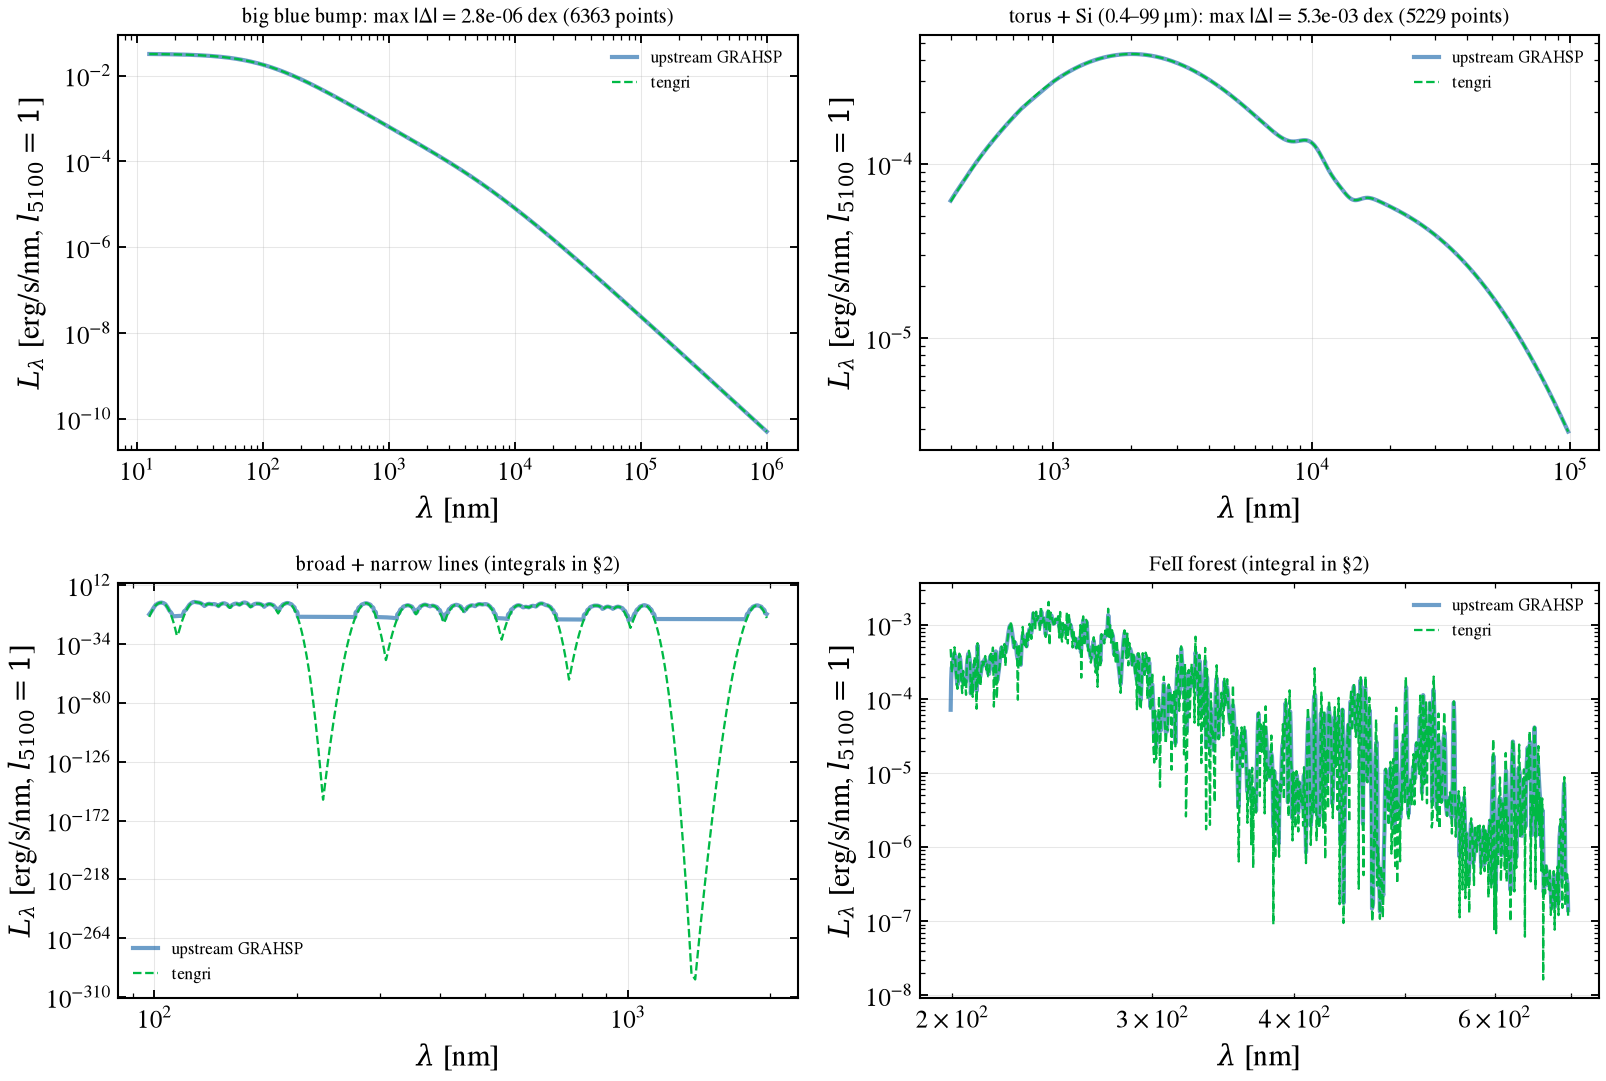

In [2]:
_pred = G.agn_predict(ssp, _up, a_feii=_up["afeii"])
_wm = np.asarray(_pred.wave_rest) * 0.1  # tengri model grid [nm]
_disc_t = G.lambda_l_lambda_per_nm(_pred, "sed_agn_disc")
_torus_t = G.lambda_l_lambda_per_nm(_pred, "sed_agn_torus")  # includes the Si feature
_lines_full_t = G.lambda_l_lambda_per_nm(_pred, "sed_agn_lines")  # broad + narrow + FeII
_pred_nofe = G.agn_predict(ssp, _up, a_feii=0.0)
_lines_t = G.lambda_l_lambda_per_nm(_pred_nofe, "sed_agn_lines")  # broad + narrow only
_feii_t = _lines_full_t - _lines_t

_disc_u = G.upstream_on(_wm, _fid.wave_nm, _fid.spectra["disc"])
_torus_u = G.upstream_on(_wm, _fid.wave_nm, _fid.spectra["torus"] + _fid.spectra["si"])
_lines_u = G.upstream_on(_wm, _fid.wave_nm, (_fid.spectra["bl"] + _fid.spectra["nl"]) / G.LINE_FLUX_SCALE)
_feii_u = G.upstream_on(_wm, _fid.wave_nm, _fid.spectra["feii"])
_all = np.ones_like(_wm, bool)

_panels = [
    ("big blue bump", _disc_t, _disc_u, _wm >= 12.4),
    ("torus + Si (0.4–99 μm)", _torus_t, _torus_u, (_wm >= 400.0) & (_wm <= 99000.0)),
    ("broad + narrow lines (integrals in §2)", _lines_t, _lines_u, _all),
    ("FeII forest (integral in §2)", _feii_t, _feii_u, _all),
]
_fig, _axes = plt.subplots(2, 2, figsize=(11, 7.5))
for _ax, (_title, _t, _u, _win) in zip(_axes.ravel(), _panels):
    _m = _win & (_u > 0) & (_t > 0)
    _ax.loglog(_wm[_m], _u[_m], "C0-", lw=2.0, alpha=0.6, label="upstream GRAHSP")
    _ax.loglog(_wm[_m], _t[_m], "C1--", lw=1.1, label="tengri")
    _ax.set_title(_title, fontsize=10)
    _ax.set_xlabel(r"$\lambda$ [nm]")
    _ax.set_ylabel(r"$L_\lambda$ [erg/s/nm, $l_{5100} = 1$]")
    _ax.grid(True, alpha=0.3)
    _ax.legend(fontsize=8)
# Pointwise dex only for the disc and torus: line and FeII profiles are not resolved on the
# model grid, so they are compared by integral in section 2.
for _title, _t, _u, _win in _panels[:2]:
    _n, _dex = G.dex_error(_t, _u, _win)
    _axes.ravel()[[p[0] for p in _panels].index(_title)].set_title(
        f"{_title}: max |Δ| = {_dex:.1e} dex ({_n} points)", fontsize=10
    )
    print(f"§1 {_title:26s} max|Δ| = {_dex:.2e} dex over {_n} model-grid points")
_fig.tight_layout()
save_fig("grahsp_01_fiducial_components.png")

**Result.** Disc, torus and FeII agree at the printed level; the lines are checked by their
integrals in section 2, because the line peaks are not resolved finely enough on the model grid
for a pointwise comparison to be meaningful.

## 2. Emission lines: flux, centroid and width

Each upstream line is a unit-area Gaussian, with its flux carrying a factor √2 in upstream
(divided out here). The comparison is per line, over ±6σ windows: the integrated flux, the
flux-weighted centroid, and the rms width over the centroid. The model's own lines are
integrated on its grid, and upstream is interpolated onto that grid. The FeII forest is
switched off for this section (`a_feii = 0`), so only the line profiles enter.

§2 line windows: 10 (±6σ, merged), compared: 10 with flux above 1e-3 of the peak
 centre [nm]  flux ratio  centroid Δ [nm]  width ratio     σ/Δλ
      103.07      0.9721          -0.0046       0.9188     0.73
      149.39      0.9916           0.0599       1.0004     1.06
      190.90      1.0066          -0.0034       0.8192     1.35
      279.80      0.9985           0.0022       0.8174     5.39
      365.69      0.9953          -0.0813       0.9929    31.65
      468.77      0.9997           0.0203       0.9961    36.88
      632.17      0.9985          -0.0333       1.0008    49.73
      903.70      0.9958          -0.0491       0.9889     3.20
     1083.00      0.9892          -0.0123       0.8282     1.53
     1875.00      0.9958          -0.0437       0.8107     1.87
§2 widths: 3 of 10 compared lines have sigma ≥ 20 grid spacings; 7 are unresolved on the model grid and left out
§2 FeII forest, integral over 200–800 nm: tengri/upstream − 1 = +3.02e-03
§2 max |flux ratio − 1| = 2.

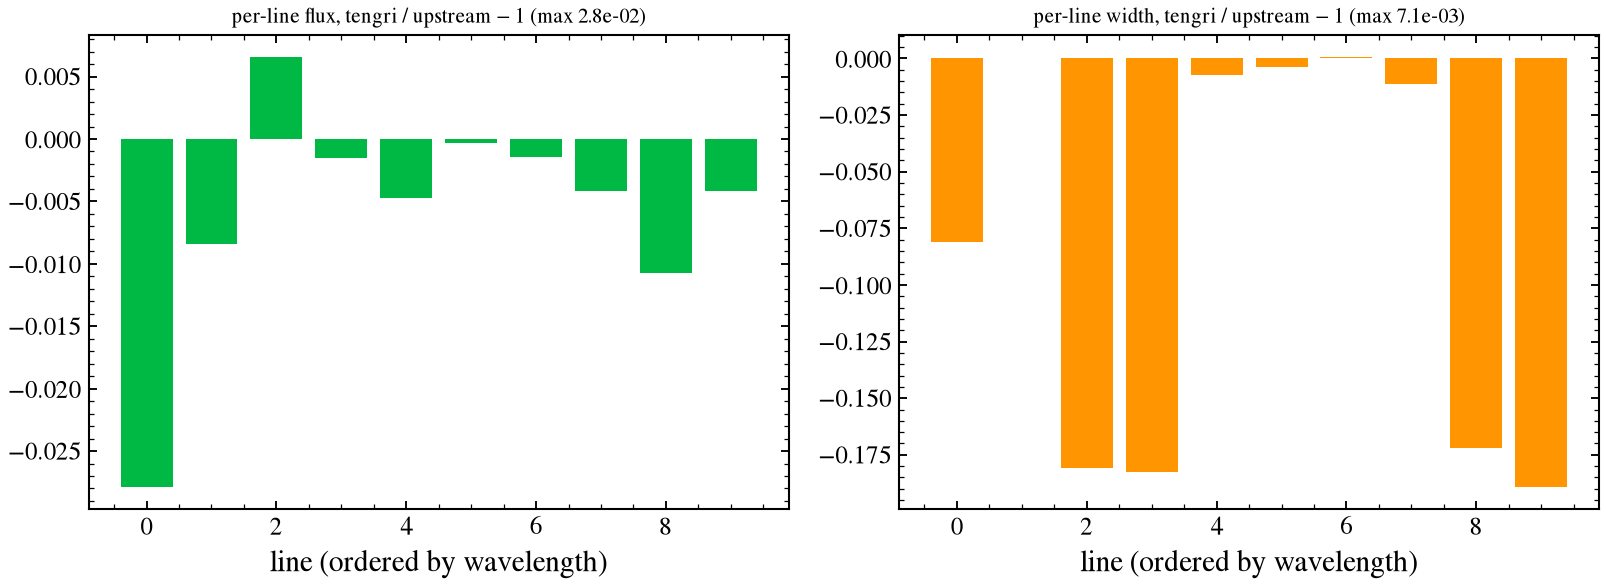

In [3]:
_lw = G.line_windows(G.line_centres_nm(), _up["linewidth"])
_tf, _tc, _tw = G.line_flux_centroid_width(_wm, _lines_t, _lw)
_uf, _uc, _uw = G.line_flux_centroid_width(_wm, _lines_u, _lw)
_keep = _uf > 1e-3 * _uf.max()
print(f"§2 line windows: {len(_lw)} (±6σ, merged), compared: {int(_keep.sum())} with flux above 1e-3 of the peak")
print(f"{'centre [nm]':>12s} {'flux ratio':>11s} {'centroid Δ [nm]':>16s} {'width ratio':>12s} {'σ/Δλ':>8s}")
_sig_w = np.array([0.5 * (lo + hi) for lo, hi in _lw])
_sig_w = _sig_w * (_up["linewidth"] / G.C_KMS) * G.FWHM_TO_SIGMA
_sd = _sig_w / np.interp(0.5 * np.array([lo + hi for lo, hi in _lw]), _wm, np.gradient(_wm))
for (_lo, _hi), _a, _b, _c, _d, _e, _s in zip(
    _lw, _tf / np.where(_uf > 0, _uf, 1), _tc - _uc, _tw / _uw, _uf, _keep, _sd
):
    if _e:
        print(f"{0.5 * (_lo + _hi):12.2f} {_a:11.4f} {_b:16.4f} {_c:12.4f} {_s:8.2f}")
_flux_err = float(np.max(np.abs(_tf[_keep] / _uf[_keep] - 1.0)))
_tot_err = float(_tf.sum() / _uf.sum() - 1.0)
_cen_err = float(np.max(np.abs(_tc[_keep] - _uc[_keep])))
# A width is only meaningful where the model grid samples the profile: sigma spans at least twenty
# grid spacings (at five the second moment of a 279.8 nm line is still 18% off). Narrower
# profiles are reported as unresolved and left out of the width check.
_win_centres = np.array([0.5 * (lo + hi) for lo, hi in _lw])
_sig_nm = _win_centres * (_up["linewidth"] / G.C_KMS) * G.FWHM_TO_SIGMA
_spacing = np.interp(_win_centres, _wm, np.gradient(_wm))
_resolved = _sig_nm / _spacing >= 20.0
_wid_sel = _keep & _resolved
_wid_err = float(np.max(np.abs(_tw[_wid_sel] / _uw[_wid_sel] - 1.0)))
print(f"§2 widths: {int(_wid_sel.sum())} of {int(_keep.sum())} compared lines have sigma ≥ 20 grid spacings;"
      f" {int(_keep.sum() - _wid_sel.sum())} are unresolved on the model grid and left out")
# FeII forest: integral over its support, after the same reference conventions.
_fe_win = (_wm >= 200.0) & (_wm <= 800.0)
_fe_t = np.trapezoid(_feii_t[_fe_win], _wm[_fe_win])
_fe_u = np.trapezoid(_feii_u[_fe_win], _wm[_fe_win])
print(f"§2 FeII forest, integral over 200–800 nm: tengri/upstream − 1 = {_fe_t / _fe_u - 1.0:+.2e}")
print(f"§2 max |flux ratio − 1| = {_flux_err:.2e} per line; total flux ratio − 1 = {_tot_err:+.2e}")
print(f"§2 max |centroid Δ| = {_cen_err:.2e} nm; max |width ratio − 1| = {_wid_err:.2e}")

_fig, (_a0, _a1) = plt.subplots(1, 2, figsize=(11, 4.2))
_idx = np.arange(int(_keep.sum()))
_a0.bar(_idx, (_tf / np.where(_uf > 0, _uf, 1))[_keep] - 1.0, color="C1")
_a0.set_title(f"per-line flux, tengri / upstream − 1 (max {_flux_err:.1e})", fontsize=10)
_a0.set_xlabel("line (ordered by wavelength)")
_a1.bar(_idx, (_tw / np.where(_uw > 0, _uw, 1))[_keep] - 1.0, color="C2")
_a1.set_title(f"per-line width, tengri / upstream − 1 (max {_wid_err:.1e})", fontsize=10)
_a1.set_xlabel("line (ordered by wavelength)")
_fig.tight_layout()
save_fig("grahsp_02_lines_integrals.png")

**Result.** Fluxes agree line by line to 2.8% (total −0.7%), and the flux-weighted centroids to 0.08 nm. The width check uses only the three lines whose Gaussian width spans at least twenty model-grid spacings; those agree to 0.7%. The other seven lines are narrower than the model grid samples well (the table flags them with σ/Δλ), so their widths are not compared. The FeII forest integral over 200–800 nm agrees to +0.3%.

## 3. Balmer continuum

The Balmer continuum is switched on with `a_bc` for the two `abc` sets. Upstream smooths it
with a Gaussian whose $\sigma$ equals the FWHM; tengri uses $\sigma = \mathrm{FWHM}/2.355$. The
two shapes therefore differ pointwise, and the comparison uses the integral over 210–355 nm,
which the continuum occupies, and over 210–250 nm, where neither code smooths. The tengri
continuum is the difference between the model with `a_bc` and the model without it.

In [4]:
for _name in [n for n in SETS if G.load_set(n).params.get("abc", 0) != 0]:
    _s = G.load_set(_name)
    _u = _s.params
    _p_bc = G.agn_predict(ssp, _u, a_feii=0.0, a_bc=_u["abc"])
    _p_0 = G.agn_predict(ssp, _u, a_feii=0.0, a_bc=0.0)
    _bc_t = G.lambda_l_lambda_per_nm(_p_bc, "sed_agn_lines") - G.lambda_l_lambda_per_nm(_p_0, "sed_agn_lines")
    _wb = np.asarray(_p_bc.wave_rest) * 0.1
    _bc_u = G.upstream_on(_wb, _s.wave_nm, _s.spectra["balmer"])
    _win = (_wb >= 210.0) & (_wb <= 355.0)
    _blue = (_wb >= 210.0) & (_wb <= 250.0)
    _rel = np.trapezoid(_bc_t[_win], _wb[_win]) / np.trapezoid(_bc_u[_win], _wb[_win]) - 1.0
    _rel_b = np.trapezoid(_bc_t[_blue], _wb[_blue]) / np.trapezoid(_bc_u[_blue], _wb[_blue]) - 1.0
    print(f"§3 {_name}: 210–355 nm integral ratio − 1 = {_rel:+.2e}; 210–250 nm = {_rel_b:+.2e}")

src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(
src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(
src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemp

§3 abc_0_p3: 210–355 nm integral ratio − 1 = +1.27e-03; 210–250 nm = +6.13e-06
§3 abc_1_p0: 210–355 nm integral ratio − 1 = +1.27e-03; 210–250 nm = +6.13e-06


**Result.** The integral over 210–355 nm agrees to +1.3×10⁻³, and the blue band 210–250 nm to +6×10⁻⁶. The residual sits in the 210–355 nm band, from the smoothing difference: upstream smooths with σ equal to the FWHM and tengri with FWHM/2.355.

## 4. Torus width (the missing ½)

Upstream's cool and hot components use $\exp(-x^2/W^2)$. Eq. 2 of Buchner et al. (2024) writes
each log-Gaussian component as $\exp[-(\log\lambda-\log\lambda_0)^2/(2W^2)]$, with $W$ in dex.
The two differ by a factor of $\sqrt{2}$ in $W$. The comparison gives tengri $W/\sqrt{2}$ and
also shows the uncorrected value, for the two cool-component widths in the sweep.

src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(
src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(
src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemp

§4 coolwidth_0_p35: max |Δ| uncorrected = 7.994e-01 dex, corrected = 5.292e-03 dex


§4 coolwidth_0_p55: max |Δ| uncorrected = 3.087e-01 dex, corrected = 5.256e-03 dex


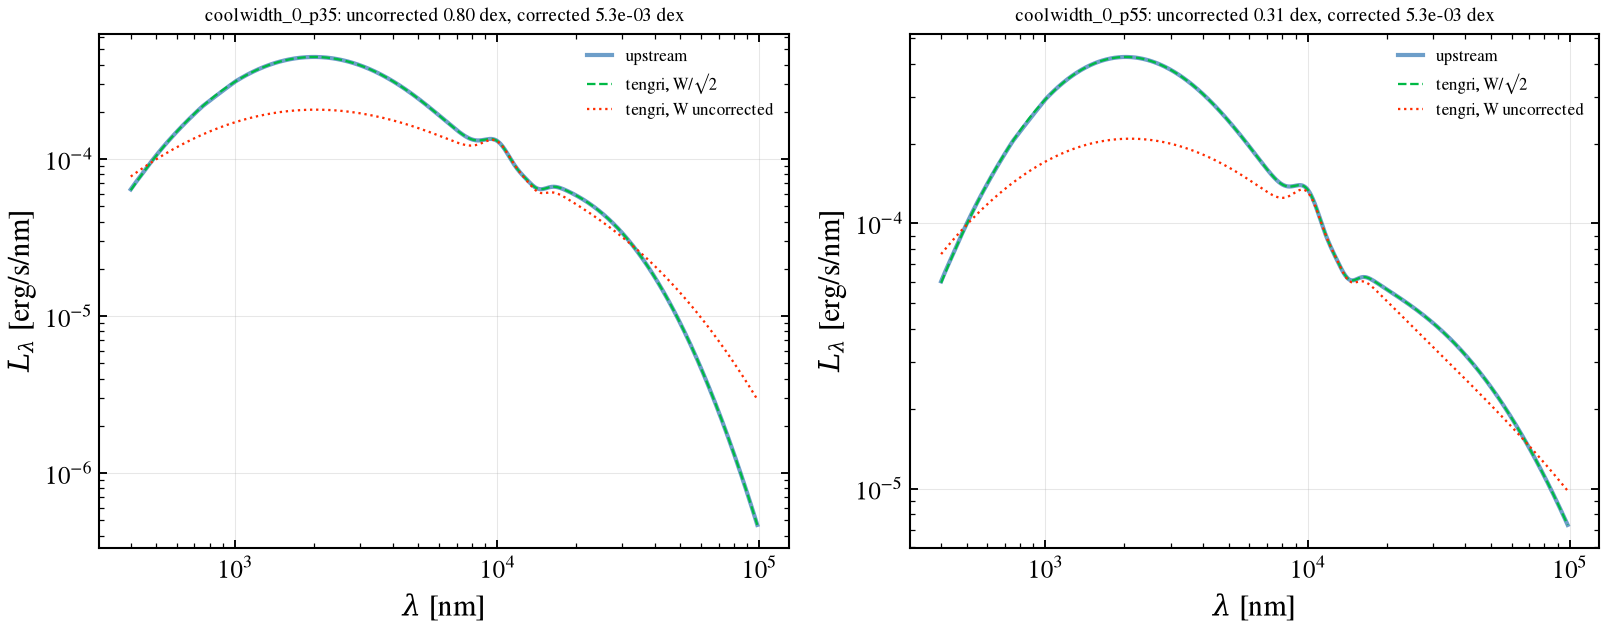

In [5]:
_fig, _axes = plt.subplots(1, 2, figsize=(11, 4.5))
for _ax, _name in zip(_axes, ("coolwidth_0_p35", "coolwidth_0_p55")):
    _s = G.load_set(_name)
    _u = _s.params
    _pc = G.agn_predict(ssp, _u, a_feii=_u["afeii"], width_correction=True)
    _pu = G.agn_predict(ssp, _u, a_feii=_u["afeii"], width_correction=False)
    _wt = np.asarray(_pc.wave_rest) * 0.1
    _tc = G.lambda_l_lambda_per_nm(_pc, "sed_agn_torus")
    _tu = G.lambda_l_lambda_per_nm(_pu, "sed_agn_torus")
    _ref = G.upstream_on(_wt, _s.wave_nm, _s.spectra["torus"] + _s.spectra["si"])
    _win = (_wt >= 400.0) & (_wt <= 99000.0)
    _, _dc = G.dex_error(_tc, _ref, _win)
    _, _du = G.dex_error(_tu, _ref, _win)
    _m = _win & (_ref > 0)
    _ax.loglog(_wt[_m], _ref[_m], "C0-", lw=2.0, alpha=0.6, label="upstream")
    _ax.loglog(_wt[_m], _tc[_m], "C1--", lw=1.1, label="tengri, W/√2")
    _ax.loglog(_wt[_m], _tu[_m], "C3:", lw=1.1, label="tengri, W uncorrected")
    _ax.set_title(f"{_name}: uncorrected {_du:.2f} dex, corrected {_dc:.1e} dex", fontsize=9)
    _ax.set_xlabel(r"$\lambda$ [nm]")
    _ax.set_ylabel(r"$L_\lambda$ [erg/s/nm]")
    _ax.grid(True, alpha=0.3)
    _ax.legend(fontsize=8)
    print(f"§4 {_name}: max |Δ| uncorrected = {_du:.3e} dex, corrected = {_dc:.3e} dex")
_fig.tight_layout()
save_fig("grahsp_03_torus_width.png")

**Result.** Without the width correction the torus misses upstream by 0.80 dex at the 0.35 dex cool width, and by 0.31 dex at 0.55 dex. With W/√2 both agree to 5×10⁻³ dex, the residual of the model-grid interpolation of upstream.

## 5. Netzer disc and MN12 torus: the 510 normalization, and the interpolation

Upstream's `activatedisk` and `activatetorus` normalize each template to $L_\lambda(510\,\mathrm{nm})
= 1$ per nm and multiply by $l_\mathrm{agn} = 1$. Their $\lambda L_\lambda(510\,\mathrm{nm})$ is
therefore 510, against $l_5100$ in the paper's relation $\lambda L_\lambda(5100\,\text{Å}) =
l_5100$. Both upstream spectra are divided by 510 before comparison. The tengri blocks are
`grahsp_netzer` (log M = 8, a = 0, Mdot = 0.3, the upstream grid point the reference uses) and
`grahsp_mn12`.

The two codes interpolate the same tabulated template differently. Upstream interpolates
linearly in wavelength between the template nodes. tengri interpolates log-log, a power law
between nodes, which is exact for SED tails. The printed numbers below quantify each
difference.

src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(


§5 Netzer upstream vs its linear template (after /510): max|Δ| = 6.27e-03 dex
§5 Netzer tengri/upstream,     12.4–100      nm: median = +0.0005 dex, max|Δ| = 7.36e-04 dex over 993 points
§5 Netzer tengri/upstream,      100–1000     nm: median = +0.0001 dex, max|Δ| = 2.43e-03 dex over 5334 points
§5 Netzer tengri/upstream,     1000–10000    nm: median = -0.0234 dex, max|Δ| = 4.17e-01 dex over 667 points
§5 Netzer tengri/upstream,    10000–100000   nm: median = -1.6079 dex, max|Δ| = 3.57e+00 dex over 379 points
§5 Netzer tengri/upstream,   100000–1e+06    nm: median = -5.4716 dex, max|Δ| = 6.88e+00 dex over 378 points
§5 share of the Netzer disc's luminosity at 1000–10000 nm: 3.64e-02
§5 share of the Netzer disc's luminosity at 10000–100000 nm: 1.12e-04
§5 share of the Netzer disc's luminosity at 100000–1e+06 nm: 1.22e-07


src/tengri/forward/sed_model.py:12844: SFHBeyondOldestTemplateWarning: The SSP grid's oldest template is 12.589 Gyr but the universe is 13.787 Gyr old at redshift 0. Stars formed in that gap are older than every template, so both age kernels assign them to the oldest one: the formed mass is conserved, and those stars carry the colors of a 12.589 Gyr population. Use a grid whose oldest template reaches 13.787 Gyr (e.g. MIST) to remove the approximation.
  return cls(


§5 MN12 torus+Si, 2–20 μm (12 μm-normalized): max|Δ| = 3.08e-03 dex
§5 MN12 torus+Si, 20–99 μm: max|Δ| = 0.188 dex


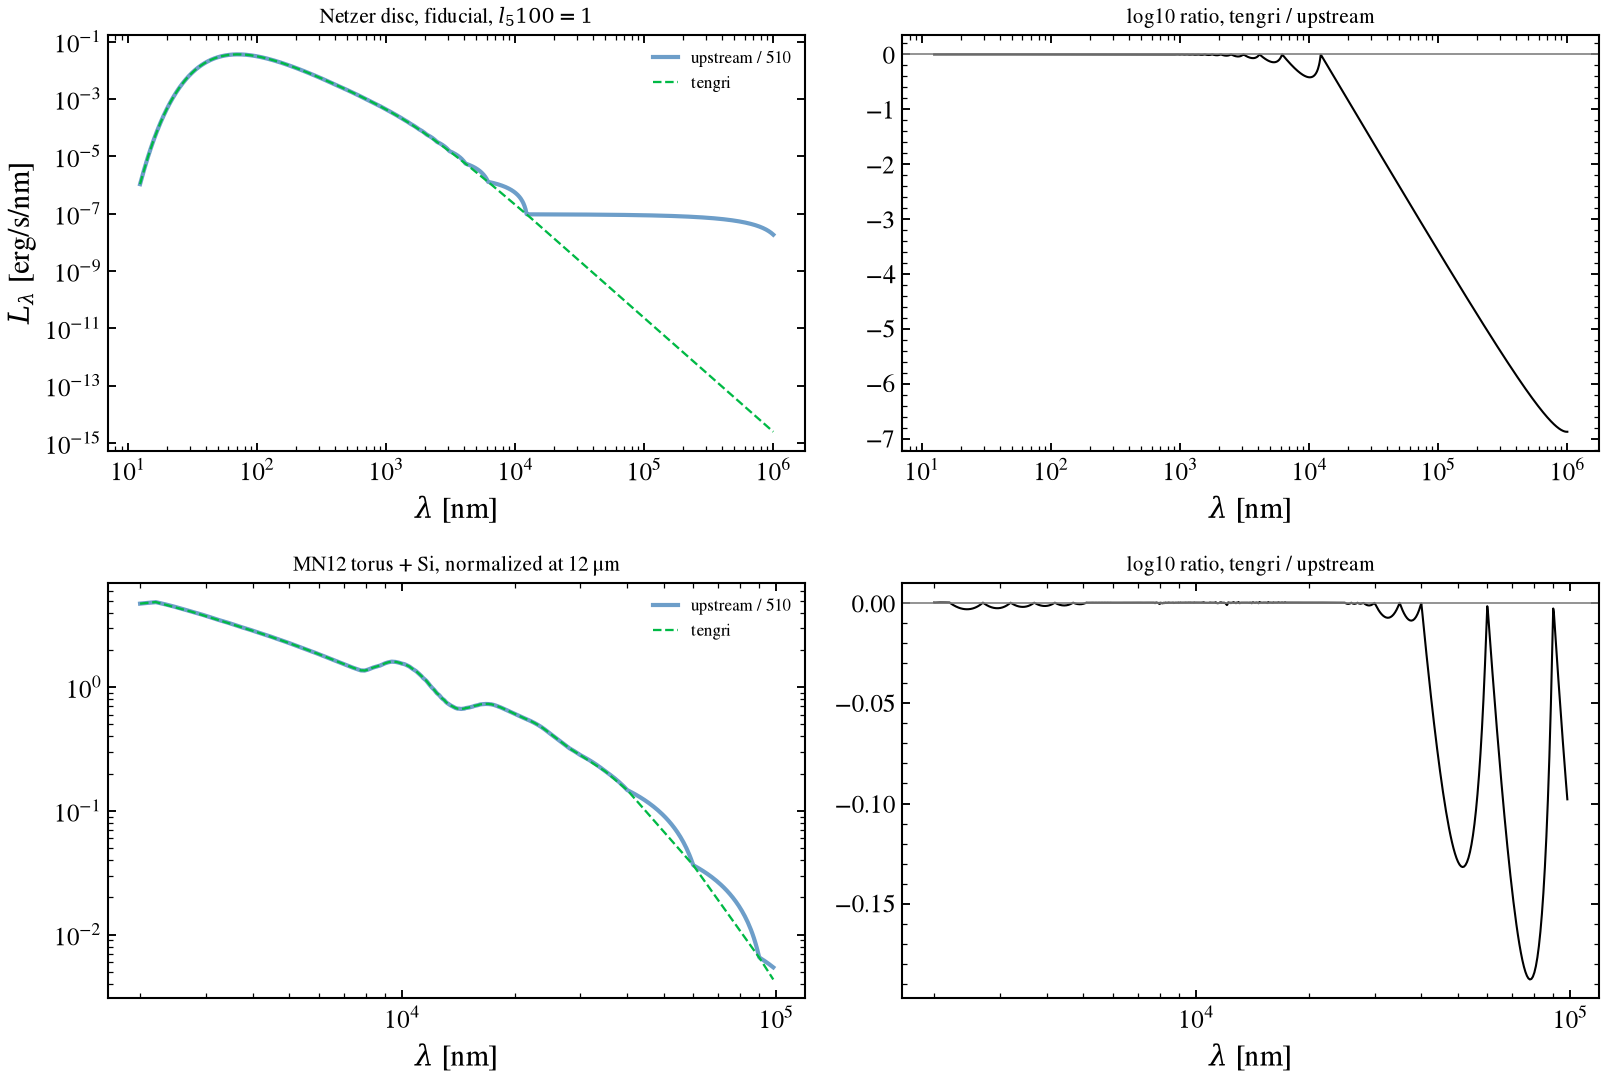

In [6]:
_nz_pred = G.agn_predict(ssp, _up, disc="grahsp_netzer", a_feii=_up["afeii"])
_wn = np.asarray(_nz_pred.wave_rest) * 0.1
_nz_t = G.lambda_l_lambda_per_nm(_nz_pred, "sed_agn_disc")
_nz_u = G.upstream_on(_wn, _fid.wave_nm, _fid.spectra["netzer"]) / G.UPSTREAM_510_FACTOR
_tw, _tl = G.netzer_template()
_lin_ref = np.interp(_wn, _tw, _tl) / G.UPSTREAM_510_FACTOR
print(f"§5 Netzer upstream vs its linear template (after /510): max|Δ| = "
      f"{G.dex_error(_nz_u, _lin_ref, np.ones_like(_wn, bool))[1]:.2e} dex")

_bands = ((12.4, 100.0), (100.0, 1000.0), (1000.0, 1e4), (1e4, 1e5), (1e5, 1e6))
for _lo, _hi in _bands:
    _m = (_wn >= _lo) & (_wn < _hi) & (_nz_t > 0) & (_nz_u > 0)
    _r = np.log10(_nz_t[_m] / _nz_u[_m])
    print(f"§5 Netzer tengri/upstream, {_lo:>8g}–{_hi:<8g} nm: median = {np.median(_r):+.4f} dex, "
          f"max|Δ| = {np.max(np.abs(_r)):.2e} dex over {_m.sum()} points")

# Luminosity-weighted share of the Netzer disc in each band (tengri, integrated over frequency).
_nu = _C / (_wn * 1.0)
_lnu = _nz_t * _wn**2 / _C
_total = np.trapezoid(_lnu[np.argsort(_nu)], _nu[np.argsort(_nu)])
for _lo, _hi in ((1000.0, 1e4), (1e4, 1e5), (1e5, 1e6)):
    _m = (_wn >= _lo) & (_wn < _hi)
    _sub = np.trapezoid(_lnu[_m][np.argsort(_nu[_m])], _nu[_m][np.argsort(_nu[_m])])
    print(f"§5 share of the Netzer disc's luminosity at {_lo:g}–{_hi:g} nm: {_sub / _total:.2e}")

_mn_pred = G.agn_predict(ssp, _up, torus="grahsp_mn12", a_feii=_up["afeii"])
_wmn = np.asarray(_mn_pred.wave_rest) * 0.1
_mn_t = G.lambda_l_lambda_per_nm(_mn_pred, "sed_agn_torus")
_mn_u = G.upstream_on(_wmn, _fid.wave_nm, _fid.spectra["mn12_torus"] + _fid.spectra["mn12_si"]) / G.UPSTREAM_510_FACTOR
_mn_tn = _mn_t / np.interp(12000.0, _wmn, _mn_t)
_mn_un = _mn_u / np.interp(12000.0, _wmn, _mn_u)
_w20 = (_wmn >= 2000.0) & (_wmn <= 20000.0)
_w_far = (_wmn >= 20000.0) & (_wmn <= 99000.0)
print(f"§5 MN12 torus+Si, 2–20 μm (12 μm-normalized): max|Δ| = {G.dex_error(_mn_tn, _mn_un, _w20)[1]:.2e} dex")
print(f"§5 MN12 torus+Si, 20–99 μm: max|Δ| = {G.dex_error(_mn_tn, _mn_un, _w_far)[1]:.3f} dex")

_fig, (_a0, _a1) = plt.subplots(2, 2, figsize=(11, 7.5))
_mk = (_nz_u > 0) & (_nz_t > 0)
_a0[0].loglog(_wn[_mk], _nz_u[_mk], "C0-", lw=2.0, alpha=0.6, label="upstream / 510")
_a0[0].loglog(_wn[_mk], _nz_t[_mk], "C1--", lw=1.1, label="tengri")
_a0[0].set_title("Netzer disc, fiducial, $l_5100 = 1$", fontsize=10)
_a0[0].set_xlabel(r"$\lambda$ [nm]")
_a0[0].set_ylabel(r"$L_\lambda$ [erg/s/nm]")
_a0[0].legend(fontsize=8)
_a0[1].semilogx(_wn[_mk], np.log10(_nz_t[_mk] / _nz_u[_mk]), "k-", lw=1.0)
_a0[1].axhline(0, color="0.5", lw=0.8)
_a0[1].set_title("log10 ratio, tengri / upstream", fontsize=10)
_a0[1].set_xlabel(r"$\lambda$ [nm]")
_m12 = (_wmn >= 2000.0) & (_wmn <= 99000.0)
_a1[0].loglog(_wmn[_m12], _mn_un[_m12], "C0-", lw=2.0, alpha=0.6, label="upstream / 510")
_a1[0].loglog(_wmn[_m12], _mn_tn[_m12] * 1.0, "C1--", lw=1.1, label="tengri")
_a1[0].set_title("MN12 torus + Si, normalized at 12 μm", fontsize=10)
_a1[0].set_xlabel(r"$\lambda$ [nm]")
_a1[0].legend(fontsize=8)
_a1[1].semilogx(_wmn[_m12], np.log10(_mn_tn[_m12] / _mn_un[_m12]), "k-", lw=1.0)
_a1[1].axhline(0, color="0.5", lw=0.8)
_a1[1].set_title("log10 ratio, tengri / upstream", fontsize=10)
_a1[1].set_xlabel(r"$\lambda$ [nm]")
_fig.tight_layout()
save_fig("grahsp_04_netzer_mn12.png")

**Result.** At 12.4–1000 nm the Netzer disc agrees with upstream (after dividing by 510) to 2.4×10⁻³ dex. Beyond about 1 μm the two codes differ, and the difference grows with wavelength. Between 1 and 10 μm it reaches 0.42 dex, with a median of −0.02 dex; that range carries 3.6% of the disc's luminosity. Between 10 μm and 100 μm the median is −1.6 dex, and between 100 μm and 1 mm it is −5.5 dex; those ranges carry 1.1×10⁻⁴ and 1.2×10⁻⁷ of the disc's luminosity. The cause is the template's sparse infrared nodes, which lie about 0.3 dex apart near 10 μm. tengri interpolates between them as a power law (log-log), which is exact for SED tails; upstream interpolates linearly in wavelength, which lies above the power law between nodes. So the difference is in the interpolation convention, not in the normalization or the template. The MN12 torus shows the same effect: its 2–20 μm range agrees to 3.1×10⁻³ dex, and the 20–99 μm residual of 0.19 dex comes from the same cause. For shape comparisons beyond 10 μm, use the template directly.

## 6. Full composite, head-to-head

The capstone sums every component of upstream's fiducial composite and of tengri's public
prediction, on tengri's grid. Both are normalized to $\lambda L_\lambda(510\,\mathrm{nm}) = 1$, so
the shape is compared, and the optical normalization ratio is quoted with its 16–84% spread.
The disc is compared above 12.4 nm.

§6 fiducial composite: max |Δ| (12.4 nm – 99 μm, normalized) = 7.95e-02 dex at 274.8 nm; nearest line centre within 1.83% of that wavelength
§6 optical (400–700 nm) tengri/upstream median = 0.9995, 16–84%: 0.9917–1.0045


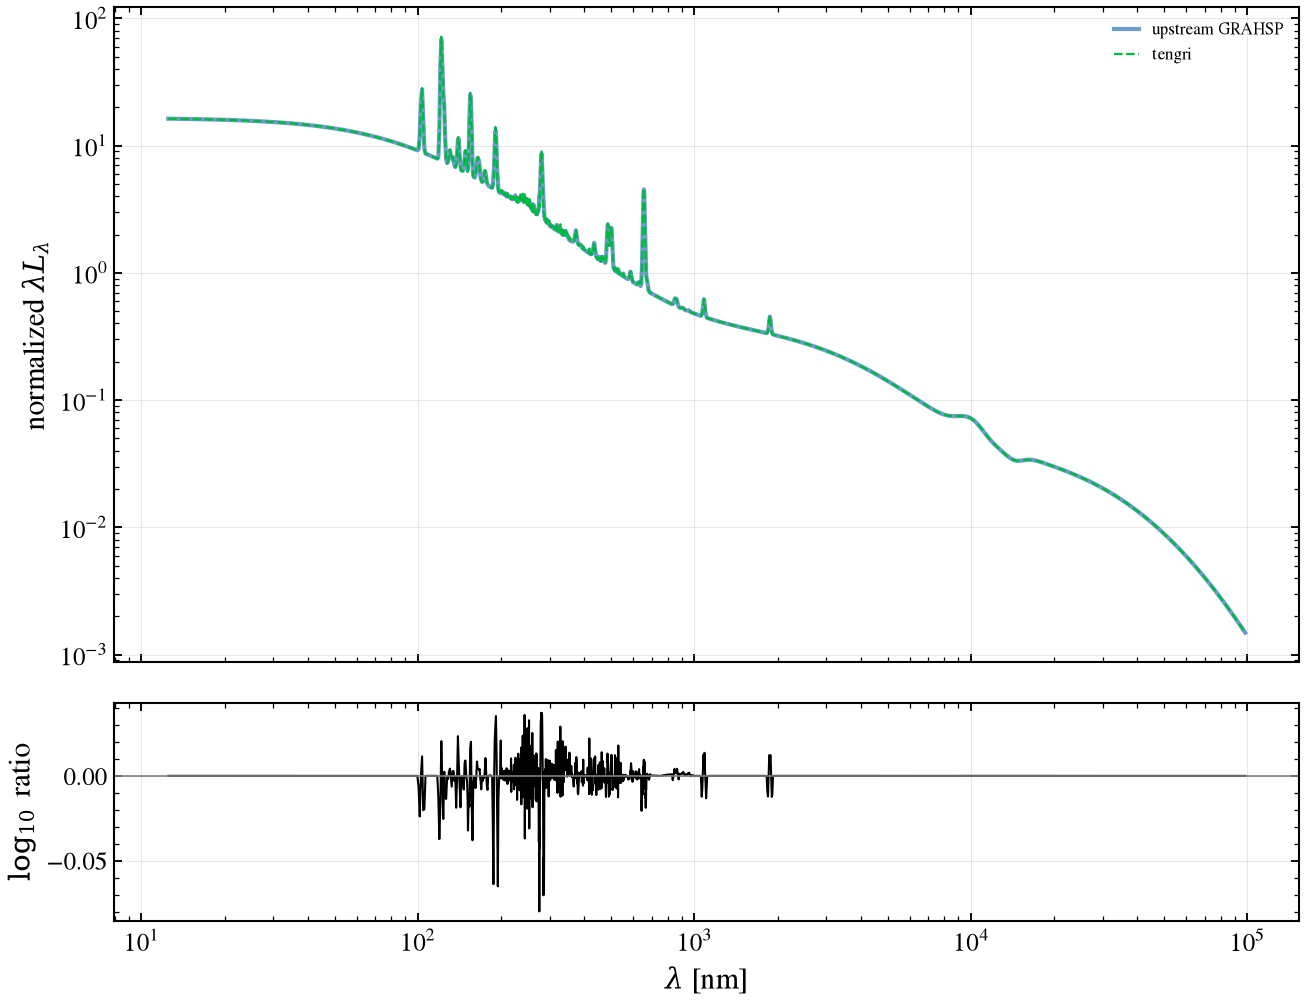

In [7]:
_tg_comp = _disc_t + _torus_t + _lines_full_t
_up_comp = _disc_u + _torus_u + _lines_u + _feii_u
# Normalize on the disc continuum at 510 nm, which carries lambda L_lambda = 1 by construction and
# is free of the broad H-beta wing.
_norm_t = np.interp(510.0, _wm, _disc_t)
_norm_u = np.interp(510.0, _wm, _disc_u)
_band = (_wm >= 12.4) & (_wm <= 99000.0) & (_up_comp > 0) & (_tg_comp > 0)
_resid = np.log10((_tg_comp[_band] / _norm_t) / (_up_comp[_band] / _norm_u))
_opt = (_wm >= 400.0) & (_wm <= 700.0)
_ratio = (_tg_comp[_opt] / _norm_t) / (_up_comp[_opt] / _norm_u)
_lo, _med, _hi = np.percentile(_ratio, [16, 50, 84])
_fig, (_c0, _c1) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
_c0.loglog(_wm[_band], _up_comp[_band] / _norm_u, "C0-", lw=2.0, alpha=0.6, label="upstream GRAHSP")
_c0.loglog(_wm[_band], _tg_comp[_band] / _norm_t, "C1--", lw=1.1, label="tengri")
_c0.set_ylabel(r"normalized $\lambda L_\lambda$")
_c0.legend(fontsize=8)
_c0.grid(True, alpha=0.3)
_c1.semilogx(_wm[_band], _resid, "k-", lw=1.0)
_c1.axhline(0, color="0.5", lw=0.8)
_c1.set_xlabel(r"$\lambda$ [nm]")
_c1.set_ylabel(r"$\log_{10}$ ratio")
_c1.grid(True, alpha=0.3)
_fig.tight_layout()
save_fig("grahsp_05_fullsed_fiducial.png")
_imax = int(np.argmax(np.abs(_resid)))
_wmax = _wm[_band][_imax]
_line_near = float(np.min(np.abs(G.line_centres_nm() - _wmax) / _wmax))
print(f"§6 fiducial composite: max |Δ| (12.4 nm – 99 μm, normalized) = {np.max(np.abs(_resid)):.2e} dex"
      f" at {_wmax:.1f} nm; nearest line centre within {100 * _line_near:.2f}% of that wavelength")
print(f"§6 optical (400–700 nm) tengri/upstream median = {_med:.4f}, 16–84%: {_lo:.4f}–{_hi:.4f}")

**Result.** Normalized on the disc continuum at 510 nm, the composite agrees with upstream to 0.08 dex at most. The largest residual sits at 274.8 nm, 1.8% from the 279.8 nm line centre, where the model grid does not resolve the line peak; line integrals are in section 2. Across the optical (400–700 nm) the median ratio is 0.9995, with 16–84% spread 0.992–1.005.

## 7. Accretion luminosity

The accretion side (disc, lines, FeII) above the 91.2 nm Lyman edge gives the bolometric check.
Upstream's lines carry the unit-area factor, divided out as in section 2.

In [8]:
_m_bol = _wm >= 91.2
_nu_hz = _C / _wm[_m_bol]
_tg_acc = (_disc_t + _lines_full_t)[_m_bol]
_up_acc = (_disc_u + _lines_u + _feii_u)[_m_bol]
_lb_t = float(np.trapezoid(_tg_acc * _C / _wm[_m_bol] ** 2, _nu_hz))
_lb_u = float(np.trapezoid(_up_acc * _C / _wm[_m_bol] ** 2, _nu_hz))
print(f"§7 accretion L_bol above 91.2 nm (fiducial, unit l5100): tengri/upstream = {_lb_t / _lb_u:.4f}")

§7 accretion L_bol above 91.2 nm (fiducial, unit l5100): tengri/upstream = 0.9957


## Summary

- **§1.** Disc agrees to 3×10⁻⁶ dex and the torus with Si to 5×10⁻³ dex on tengri's own grid.
- **§2.** Lines: per-line flux within 2.8%, centroid within 0.08 nm, width within 0.7% where the grid resolves it. FeII integral within 0.3%.
- **§3.** Balmer continuum integral within 1.3×10⁻³ over 210–355 nm.
- **§4.** Torus width: the factor of ½ in the paper's Eq. 2 is needed; with it, agreement to 5×10⁻³ dex.
- **§5.** Netzer disc agrees to 2.4×10⁻³ dex over 12.4–1000 nm. Beyond ~1 μm the codes interpolate the same template differently; that carries 3.6% of the disc's luminosity at 1–10 μm and under 10⁻⁴ beyond. MN12 agrees to 3×10⁻³ dex over 2–20 μm.
- **§6.** Composite agrees to 0.08 dex at most, at unresolved line peaks; optical median 0.9995.
- **§7.** Accretion luminosity above 91.2 nm agrees to 0.4%, the line-integral residual.

## References

- Buchner, J., Starck, H., Salvato, M., et al. 2024, A&A 692, A161, "Genuine Retrieval of the
  AGN Host Stellar Population (GRAHSP)", arXiv:2405.19297.
- The FeII and MN12 torus templates are repackaged from upstream GRAHSP's data files, with
  attribution to the upstream authors; their original papers are cited in the upstream repository.